# Baseline Evaluation: Split Levels, Leakage Check and Plots
Owner: Anupama Singh

Uses the shared loader in `src/data.py`.

1. School-level vs student-level evaluation
2. Leakage check: what happens if we add features measured during the year
3. Plots: predicted vs actual gain, and the Decision Tree

## Setup

In [1]:
import sys; sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import roc_auc_score, mean_absolute_error, mean_squared_error

from src.data import load_labeled, FALL_FEATURES, IN_YEAR_FEATURES, TARGETS, get_cv

df = load_labeled()
print("Labeled students:", len(df), "| Schools:", df["SchlID"].nunique())

Labeled students: 946 | Schools: 44


## Models
Same settings as notebooks 01 and 02. Decision Tree depth 2 was the best depth in both.

In [2]:
MODELS = {
    "Logistic Regression": ("clf", lambda: make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))),
    "Decision Tree": ("clf", lambda: make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(max_depth=2, min_samples_leaf=20, random_state=0))),
    "Linear Regression": ("reg", lambda: make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())),
    "Decision Tree Regressor": ("reg", lambda: make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeRegressor(max_depth=2, min_samples_leaf=20, random_state=0))),
}

def evaluate(features, level):
    """Run every model on both targets. Returns one row per (target, model)."""
    cv, uses_groups = get_cv(level)
    groups = df["SchlID"] if uses_groups else None
    X = df[features]
    rows = []
    for target_name, score in TARGETS.items():
        label, gain = df[f"{score}_target"], df[f"{score}_gain"]
        for model_name, (kind, make) in MODELS.items():
            if kind == "clf":
                p = cross_val_predict(make(), X, label, cv=cv, groups=groups, method="predict_proba")[:, 1]
                mae = rmse = None
            else:
                p = cross_val_predict(make(), X, gain, cv=cv, groups=groups)
                mae = round(mean_absolute_error(gain, p), 2)
                rmse = round(mean_squared_error(gain, p) ** 0.5, 2)
            rows.append({"target": target_name, "model": model_name,
                         "AUC": round(roc_auc_score(label, p), 3), "MAE": mae, "RMSE": rmse})
    return pd.DataFrame(rows)

## 1. School-level vs student-level split
- **School level:** test schools are never seen in training (harder, more realistic for a new school).
- **Student level:** random students; the same school can be in train and test.

In [3]:
school = evaluate(FALL_FEATURES, "school").assign(split="school")
student = evaluate(FALL_FEATURES, "student").assign(split="student")
split_results = pd.concat([school, student])
split_results.to_csv("../results/split_comparison.csv", index=False)
split_results.pivot_table(index=["target", "model"], columns="split", values="AUC")

split                                        school  student
target              model                                   
Word Attack         Decision Tree             0.554    0.554
                    Decision Tree Regressor   0.536    0.555
                    Linear Regression         0.627    0.637
                    Logistic Regression       0.627    0.626
Word Identification Decision Tree             0.580    0.611
                    Decision Tree Regressor   0.574    0.601
                    Linear Regression         0.670    0.681
                    Logistic Regression       0.657    0.677

## 2. Leakage check
Add the 4 features measured **during** the school year and compare (school-level split).

If AUC jumps a lot, those features carry information from after the prediction point and should stay out of the main results.

In [4]:
fall_only = evaluate(FALL_FEATURES, "school").assign(features="fall only")
with_in_year = evaluate(FALL_FEATURES + IN_YEAR_FEATURES, "school").assign(features="+ in-year")
leak = pd.concat([fall_only, with_in_year])
leak.to_csv("../results/leakage_check.csv", index=False)
table = leak.pivot_table(index=["target", "model"], columns="features", values="AUC")
table["change"] = (table["+ in-year"] - table["fall only"]).round(3)
table

features                                     + in-year  fall only  change
target              model                                                
Word Attack         Decision Tree                0.526      0.554  -0.028
                    Decision Tree Regressor      0.538      0.536   0.002
                    Linear Regression            0.622      0.627  -0.005
                    Logistic Regression          0.624      0.627  -0.003
Word Identification Decision Tree                0.587      0.580   0.007
                    Decision Tree Regressor      0.551      0.574  -0.023
                    Linear Regression            0.666      0.670  -0.004
                    Logistic Regression          0.657      0.657   0.000

## 3a. Plot: predicted vs actual gain (Linear Regression, school-level split)

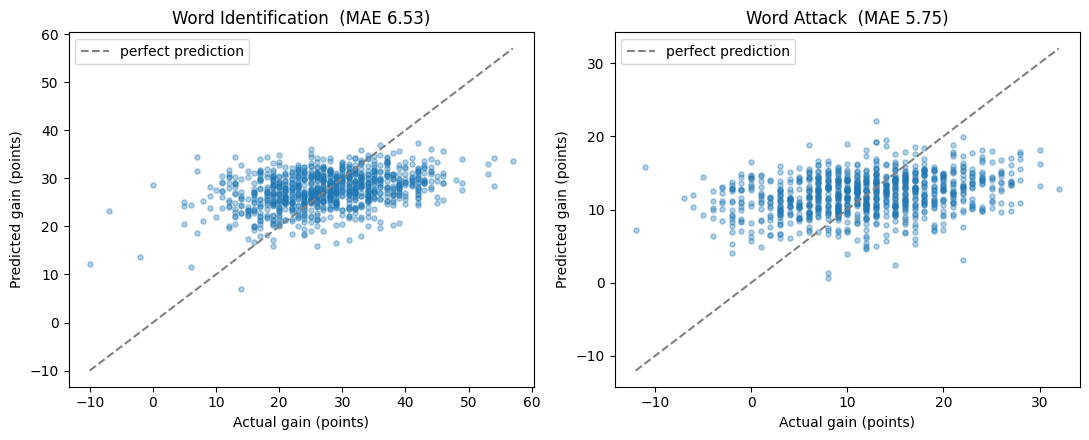

In [5]:
cv, _ = get_cv("school")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (target_name, score) in zip(axes, TARGETS.items()):
    gain = df[f"{score}_gain"]
    pred = cross_val_predict(MODELS["Linear Regression"][1](), df[FALL_FEATURES], gain,
                             cv=cv, groups=df["SchlID"])
    ax.scatter(gain, pred, alpha=0.35, s=14)
    lo, hi = gain.min(), gain.max()
    ax.plot([lo, hi], [lo, hi], color="gray", linestyle="--", label="perfect prediction")
    ax.set_title(f"{target_name}  (MAE {mean_absolute_error(gain, pred):.2f})")
    ax.set_xlabel("Actual gain (points)")
    ax.set_ylabel("Predicted gain (points)")
    ax.legend()
plt.tight_layout()
plt.savefig("../results/pred_vs_actual_gain.png", dpi=150)
plt.show()

## 3b. Plot: the Decision Tree (Word Identification)
Trained on all labeled students, so we can read which splits it uses.

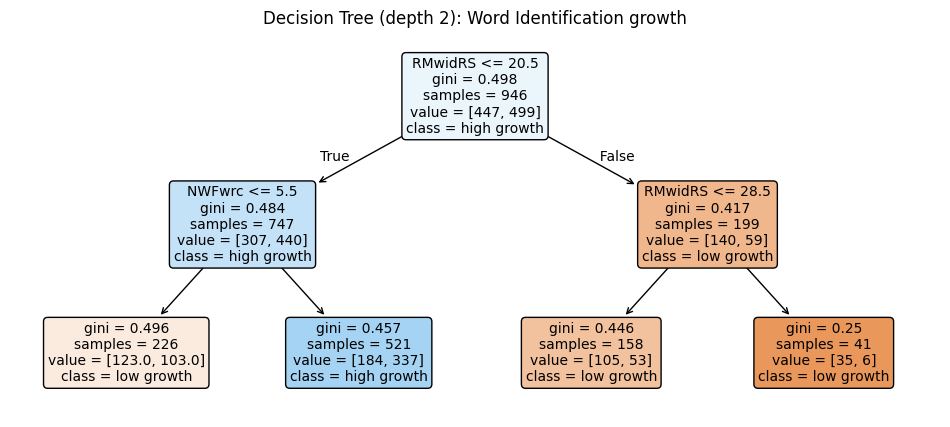

In [6]:
tree = MODELS["Decision Tree"][1]().fit(df[FALL_FEATURES], df["RMwidRS_target"])
plt.figure(figsize=(12, 5))
plot_tree(tree[-1], feature_names=FALL_FEATURES, class_names=["low growth", "high growth"],
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree (depth 2): Word Identification growth")
plt.savefig("../results/decision_tree_word_id.png", dpi=150, bbox_inches="tight")
plt.show()